In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/Amapolaa/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [28]:
# FINAL CODE
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

#Downloading the NY spills csv
fp = 'data/Spill_Incidents_20261102.csv'
spills = pd.read_csv(fp)

#downloading US counties
#changed 'fp' to c bc it wouldnt run the file :(
c = os.path.join('data/tl_2026_us_county.shp')
counties = gpd.read_file(c)

##SPILLS##
#change names to lowercase then replace any spaces that have underscores
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

#change the datetimes
spill_dates = spills[['spill_date','received_date','close_date']] = spills[['spill_date','received_date','close_date']].astype("datetime64[ns]")

#remove the commas from quantity and recovered col
spills['quantity'] = spills['quantity'].replace(',','', regex = True)
spills['recovered'] = spills['recovered'].replace(',','', regex = True)

#change string numbers into floats
spills[['quantity','recovered']] = spills[['quantity','recovered']].astype('float64')

##DATA SELECTION ##
#filter petroleum spills
petr_23 = spills[spills['material_family'] == 'Petroleum']

#.between('jan 1 - dec 31, 2023') both dates
petr_23 = spills[(spills['material_family'] == 'Petroleum') & spills['spill_date'].between('2023-01-01','2023-12-31')]

##Data aggregation
spills_per_county = petr_23.groupby('county').nunique('spill_number')['spill_number'].reset_index()

#rename the spill_number to n_spills
spills_per_county = spills_per_county.rename(columns ={'spill_number': 'n_spills'})

#COUNTIES##
#change them to lowercase
counties.columns = counties.columns.str.lower()

#select al counties from ny and plot them
counties[counties['name'] == 'new york']

ny_counties = counties[counties['statefp'] == '36']

## MERGING
#print counties without repitition
ny_counties['name'].unique()

# before comparing
spill_count = spills_per_county['county'].dropna().astype(str).unique()

#check
spill_count

# need to do the same for ny counties
ny_names = ny_counties["name"].dropna().astype(str).unique()

diff_names_spills = np.setdiff1d(spill_count, ny_names)
diff_names_ny = np.setdiff1d(ny_names,spill_count)

ny_counties = ny_counties.rename(columns= {'name':'county'})

#merge counties and spills data together in ny_spills (pd.merge)
ny_spills = pd.merge(ny_counties, spills_per_county,
                     on='county',how='inner')

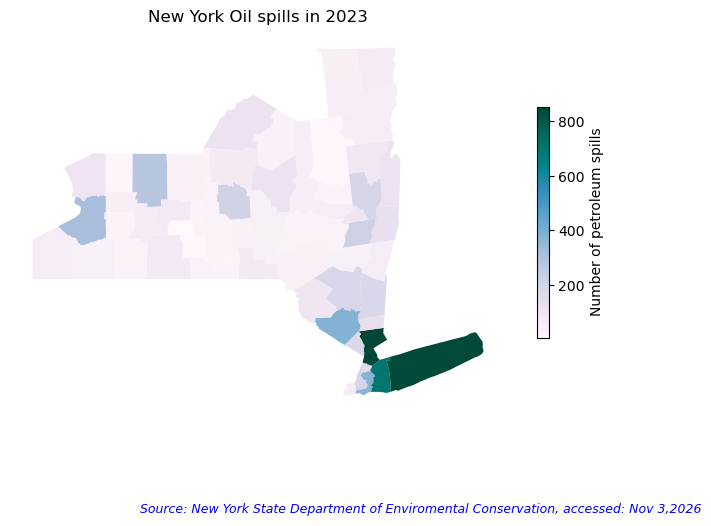

In [29]:

#map
# Create choropleth map 
#creates the plot
fig, ax = plt.subplots(figsize=(8,6))

#removes the axis for cleaner map
ax.axis('off')

#creating the Choropleth Map
ny_spills.plot(
    ax=ax,
    column='n_spills',
    cmap='PuBuGn',
    legend=True,
    legend_kwds={'label': 'Number of petroleum spills', 'shrink': 0.5},
    linewidth=0.5)

#add title and remove axis grid
ax.set_title("New York Oil spills in 2023")
ax.set_axis_off();

# #add titles and move 
fig.text(
    0.99,
    0.01,
    "Source: New York State Department of Enviromental Conservation, accessed: Nov 3,2026",
    ha="right",
    fontsize=9,
    color="blue",
    style="italic"
)

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [ ]:
#Downloading the NY spills csv
fp= 'data/Spill_Incidents_20261102.csv'
spills = pd.read_csv(fp)

#downloading US counties
#changed 'fp' to c bc it wouldnt run the file :(
c = os.path.join('data/tl_2026_us_county.shp')
counties = gpd.read_file(c)

In [ ]:
counties

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [ ]:
#a. Check the dataframe's head
spills.head()

In [ ]:
#b. Check the data types of the columns
spills.dtypes

In [ ]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique() 

In [ ]:
#d. Check the unique values in the `county` column
spills['County'].unique()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [ ]:
#change names to lowercase then replace any spaces that have underscores
spills.columns = spills.columns.str.lower().str.replace(' ', '_')
spills

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [ ]:
#Change them to datetime obj
spill_dates = spills[['spill_date','received_date','close_date']] = spills[['spill_date','received_date','close_date']].astype("datetime64[ns]")
spill_dates

In [ ]:
#remove the commas from quantity and recovered col
spills['quantity'] = spills['quantity'].replace(',','', regex = True)
spills['recovered'] = spills['recovered'].replace(',','', regex = True)

#change string numbers into floats
spills[['quantity','recovered']] = spills[['quantity','recovered']].astype('float64')

#check
spills[['quantity', 'recovered']].head(4) #success!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [ ]:
#want to see what col 'petroleum' is at
spills.head(4)

In [ ]:
#filter 'petroleum' from Material family
petr_23 = spills[spills['material_family'] == 'Petroleum']

#check
#petr_23

#.between('jan 1 - dec 31, 2023') both dates
petr_23 = spills[(spills['material_family'] == 'Petroleum') & spills['spill_date'].between('2023-01-01','2023-12-31')]

#check
petr_23

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [ ]:
#use print(f'string')
print(f"petr_23 has only data for the year {petr_23['spill_date'].dt.year.unique()}")

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [ ]:
#assert func
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [ ]:
print(f"There are: {len(petr_23)} rows and {(petr_23['spill_number'].nunique())} unique spills." )


In [ ]:
#checking the values in spill num
petr_23['spill_number'].value_counts()

* The counts aren't the same but by looking at the data there are multiple entries that do have the name `material_name` for each of the petroleum spills.

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [ ]:
petr_23.head()

In [ ]:
#use the nunique() value for num of petr spills per country from jan 1 to dec 2023
#col 1 is county names: groupby()
#col 2 is num of petr in 2023 (nunique)
spills_per_county = petr_23.groupby('county').nunique('spill_number')['spill_number'].reset_index()

#check
#spills_per_county 

#rename the spill_number to n_spills
spills_per_county = spills_per_county.rename(columns ={'spill_number': 'n_spills'})

#check
spills_per_county

In [ ]:
grader.check("q5d")

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [ ]:
# a.head()
counties.head(4)

In [ ]:
# b.dtypes
counties.dtypes

In [ ]:
# c. checking the CRS
print(counties.crs)

In [ ]:
# d plt counties
counties.plot() #too far away

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [ ]:
#check column names
counties.columns

# need to lowercase them

In [ ]:
#change them to lowercase
counties.columns = counties.columns.str.lower()

#check
counties.columns

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [ ]:
#select al counties from ny and plot them
counties[counties['name'] == 'new york']

ny_counties = counties[counties['statefp'] == '36']

#check work
print(ny_counties['statefp'])

In [ ]:
ny_counties.plot();

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
#ny_counties['name']

In [ ]:
#print counties without repitition
ny_counties['name'].unique()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [ ]:
##dropped na bc setdiff1d() recieved polygon with str
# did the same below
spills_per_county['county'].unique()

In [ ]:
#drop na
ny_counties['name'].unique()

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
#came across an error where spill_per_county has str and int
#need to drop na and change them to strings 
# before comparing
spill_count = spills_per_county['county'].dropna().astype(str).unique()

#check
spill_count

# need to do the same for ny counties
ny_names = ny_counties["name"].dropna().astype(str).unique()

#check
ny_names

In [ ]:
#check all unique names in spills that are not in ny_count

diff_names_spills = np.setdiff1d(spill_count, ny_names)

diff_names_spills

In [ ]:
grader.check("7Ac")

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
#check whats not in one dataframe than the other
#just had to switch names :)
diff_names_ny = np.setdiff1d(ny_names,spill_count)
diff_names_ny

In [ ]:
grader.check("7Ad")

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. numb of spills
#using isin() in county col
spills_per_county[spills_per_county['county'].isin(['Tuscarora Indian Reservation','Onondaga Indian Reservation'])]

### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [ ]:
#verfy update
spills_per_county['county'].tolist() # its  'St Lawrence'

In [ ]:
#located the index
spills_per_county['county'].tolist().index('St Lawrence') # 52

In [ ]:
# change the name to st.lawrence with the index
spills_per_county.loc[52,'county']= 'St. Lawrence'

In [ ]:
#check the update with assert
assert spills_per_county.loc[52,'county']== 'St. Lawrence'

In [ ]:
#just wanted to check if the change was there
spills_per_county['county'].tolist()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [ ]:
# a rename name to county
#ny_counties['name'].tolist()
ny_counties = ny_counties.rename(columns= {'name':'county'})
#so i didnt use it and no need to update

In [ ]:
ny_counties

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [ ]:
#merge counties and spills data together in ny_spills (pd.merge)
ny_spills = pd.merge(ny_counties, spills_per_county,
                     on='county',how='inner')

#check
ny_spills

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [ ]:
#print(f"rows in spills_per_county: {len(spills_per_county)}") #66
#print(f"rows in ny_counties: {len(ny_counties)}") #62
#print(f"rows in ny_spills: {len(ny_spills)}") #62

In [ ]:
#check to see what records were dropped from spills_per_county by innerjoin
dropped_ny = np.setdiff1d(spills_per_county['county'].unique(), ny_spills['county'].unique())
dropped_ny

#see how many spills each county had
spills_per_county[spills_per_county['county'].isin(dropped_ny)]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

**By comparing the county names, we know that the four above will not appear in the innerjoin. The reservation records are in the Niagara and Onondaga counties,therefore unfortunatley they will not be in our map data. The spills may be missing from the county total unless they are matched into the correct counties. Small discrepancies like this cause a massive issues.**

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
#gettting spills from Tuscarora reservation
tusc_spills = spills_per_county.iat[58,1]

tusc_spills

In [ ]:
#getting spills from Onondaga Indian Reservation
ono_spills = spills_per_county.iat[35,1]

ono_spills

In [ ]:
# verify that the number goes up to 8220 (more spills were included back into the ny_spi;;s)
ny_spills['n_spills'].sum()

In [ ]:
#add Tuscarora Inndian reservation number spills to niagara county 
#and oganada inisan reservation num spills
ny_spills.loc[ny_spills['county'] == 'Niagrara','n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + tusc_spills
ny_spills.loc[ny_spills['county'] == 'Onondaga','n_spills']= ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + ono_spills

In [ ]:
#dbl checking the number changes to 8220
ny_spills['n_spills'].sum()

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



In [ ]:
ny_spills['n_spills'].sum()

In [ ]:
# Create choropleth map 
#creates the plot
fig, ax = plt.subplots(figsize=(8,6))

#removes the axis for cleaner map
ax.axis('off')

#creating the Choropleth Map
ny_spills.plot(
    ax=ax,
    column='n_spills',
    cmap='PuBuGn',
    legend=True,
    legend_kwds={'label': 'Number of petroleum spills', 'shrink': 0.5},
    linewidth=0.5)
    
  




#add title and remove axis grid
ax.set_title("New York Oil spills in 2023")
ax.set_axis_off();

# #add titles and move 
fig.text(
    0.99,
    0.01,
    "Source: New York State Department of Enviromental Conservation, accessed: Nov 3,2026",
    ha="right",
    fontsize=9,
    color="blue",
    style="italic"
)

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.


**Note:** Creating my map was a bit harder than it shouldve been. I had an issue where when i tried to plot `ny_spills`, it kept saying there was an issue with geopandas. Never the less, I did find the issue, it was the order of how I setted up my innerjoin line of code. It was a good experience for learning!!

8b.
---
To create my map, I filtered the 2023 spill records to include only petroleum spills reported in New York state. I then prepared the corresponding county boundary data and standardized the county names to ensure consistency between datasets and joined the spill counts geographically while preserving the integrity of the county shapes. The map does not represent the three reservation spill as distinct locations. The Census Bureau county data I used excluded the Tuscarora and Onondaga reservations as county areas, so I assigned the two Tuscarora spills to Niagara County and the Onondaga spill to Onondaga County. Although this approach allowed the spills to be visualized on the map, it obscures their association with the reservations. This raises concerns regarding the representation of Indigenous lands and data, particularly in relation to the CARE principle of *“Authority to Control.”* For future mapping efforts, I would incorporate reservation boundaries from the outset and collaborate with the relevant Indigenous communities to determine appropriate data representation.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.